In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import imblearn
import sklearn
import pickle

import sklearn.decomposition as skdecomp
import sklearn.ensemble as skens
import sklearn.svm as sksvm
import sklearn.linear_model as sklin

from sklearn.model_selection import GridSearchCV,StratifiedGroupKFold,StratifiedKFold,KFold
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest

from pychemauth.classifier.simca import SIMCA_Authenticator
from pychemauth.manifold.elliptic import EllipticManifold_Authenticator
from pychemauth.classifier.plsda import PLSDA
#from pychemauth.analysis.compare import Compare
from pychemauth.preprocessing.scaling import CorrectedScaler

from pychemauth.classifier.osr import OpenSetClassifier

from pychemauth_compare_ext import Compare_reg,make_boxplot,order_results,results_perform

2026-08-28 15:13:24.081725: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import multiphase_flow_utils
from multiphase_flow_utils import generate_models,extract_best_estimator
from multiphase_flow_utils import read_and_split_file,strip_constant,prune_threshold
from multiphase_flow_utils import fit_models,generate_kfolds,cross_validate
from multiphase_flow_utils import generate_kfolds,cross_validate,compute_scores
from multiphase_flow_utils import compute_fit,compute_vals,plot_fit,plot_vals

In [3]:
file = 'combined_diagnostic.xlsx'
dataset_num = 'Diagnostic'
#combined_diagnostic_velratio_vs_0.5_study.pkl
study_pickle_file = file.split('.')[0] + '_velratio_vs_0.6_study.pkl'
ydata_col = 'Erro ([%])'

with open(study_pickle_file,'rb') as f:
    print(study_pickle_file)
    this_study = pickle.load(f)
print(this_study.train[0].shape)

combined_diagnostic_velratio_vs_0.6_study.pkl
(487, 51)


In [4]:
def calibration_plots(study_data,study_predict,color='r'):
    x,y = study_data
    predicted = study_predict(x)
    
    nplots = len(predicted)
    fig,axs = plt.subplots(nplots,2,figsize=(8,2*(nplots+1)),squeeze=False)
    
    for (name,pred),ax_cal,ax_res in zip(predicted.items(),axs[:,0],axs[:,1], ):
        ax_cal.plot(
            y,pred,
            ls='none',marker='o',markersize=1,color=color
        )

        cal_line_limits = ax_cal.get_xticks()[[0,-1]]
        ax_cal.plot(cal_line_limits,cal_line_limits,color='k',lw=2)
        ax_cal.set_xlim(cal_line_limits)
        ax_res.plot(
            y,pred[:,None]-y.values,
            ls='none',marker='o',markersize=1,color=color
        )
        ax_cal.text(0.05,0.9,name,transform=ax_cal.transAxes)
        
def cvs_plots(study_data,cvs_dict,kfold_repeats,color='r'):
    x,y = study_data
    
    yt = np.squeeze(y.values)
    #cvs_dict = this_study.cvs_dict
    #n_repeats = this_study.kfold_repeats

    nplots = len(cvs_dict)
    fig,axs = plt.subplots(nplots,2,figsize=(8,2*nplots+0.5),squeeze=False)

    for (name,cvs),ax_cal,ax_res in zip(cvs_dict.items(),axs[:,0],axs[:,1], ):

        coefs,covar,fit_err = compute_fit(yt,cvs,kfold_repeats)

        plot_vals(ax_cal,yt,cvs,color=color)
        plot_vals(ax_res,yt,cvs,resid=True,color=color)

        plot_fit(ax_cal,coefs,covar,fit_err)
        ax_cal.text(0.05,0.9,name,transform=ax_cal.transAxes)
    return fig,axs
        

In [5]:
def calibration_plots(y,predicted,axs,size=1,color='r',label=None):
    #x,y = study_data
    #predicted = study_predict(x)
    
    #nplots = len(predicted)
    #fig,axs = plt.subplots(nplots,2,figsize=(8,2*nplots))
    
    for (name,pred),ax_cal,ax_res in zip(predicted.items(),axs[:,0],axs[:,1], ):
        ax_cal.plot(
            y,pred,
            ls='none',marker='o',markersize=size,color=color,
            label=label
        )

        cal_line_limits = ax_cal.get_xticks()[[0,-1]]
        ax_cal.plot(cal_line_limits,cal_line_limits,color='k',lw=2,zorder=-1)
        ax_cal.set_xlim(cal_line_limits)
        ax_res.plot(
            y,pred[:,None]-y.values,
            ls='none',marker='o',markersize=size,color=color
        )
        ax_cal.text(0.05,0.9,name,transform=ax_cal.transAxes)

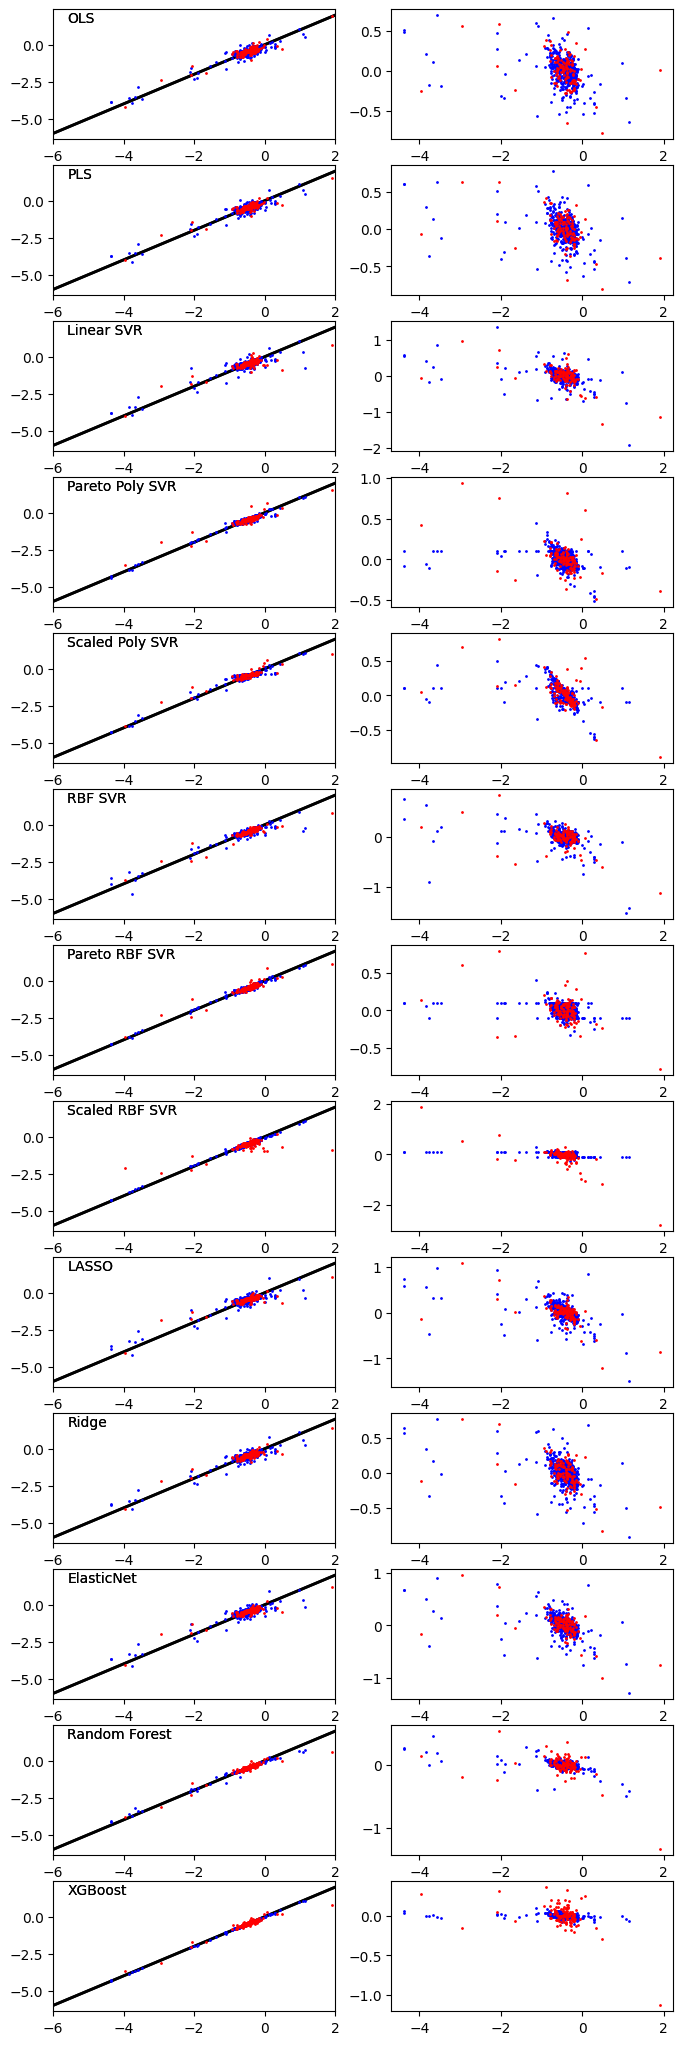

In [6]:
xtr,ytr = this_study.train
xte,yte = this_study.test

pred_tr = this_study.all_predict(xtr)
pred_te = this_study.all_predict(xte)

nplots = len(pred_tr)
fig,axs = plt.subplots(nplots,2,figsize=(8,2*nplots))

calibration_plots(ytr,pred_tr,axs,color='b')
calibration_plots(yte,pred_te,axs,color='r')

In [7]:
pred_tr

{'OLS': array([-0.12962721, -0.36046811, -0.48836853, -0.90032233, -0.06714479,
        -0.19931306,  0.67886927, -0.38237806, -0.69153346, -0.17436024,
        -0.1586229 , -0.5071304 , -0.69070176, -0.40458049, -1.92957511,
        -0.2742558 , -0.48495574, -0.25919056, -0.41943713, -0.40735058,
        -0.62365373, -0.1067276 ,  0.08608932, -0.24118058, -0.593662  ,
        -0.27141358, -0.41144862, -0.76217837, -0.47519987, -0.79579184,
        -0.34305997, -0.37884712, -0.20674421, -0.54984274, -0.2128693 ,
        -0.37571219, -0.22940009, -0.45481232, -0.32430767, -0.36778979,
        -0.13150525, -0.56885583, -0.61280773, -0.37108202, -3.6277518 ,
        -0.3658188 , -0.39302231, -0.42719363, -0.06340094, -0.31986782,
        -0.47607529, -0.73393272, -0.43907993, -0.14909317, -0.49979066,
        -0.73509989, -0.29316436, -0.12112354, -0.5465171 , -1.60749157,
        -0.65953188, -0.51191801, -0.31441356, -0.83100554, -0.35753977,
        -0.62257448, -0.30565151, -0.1185131

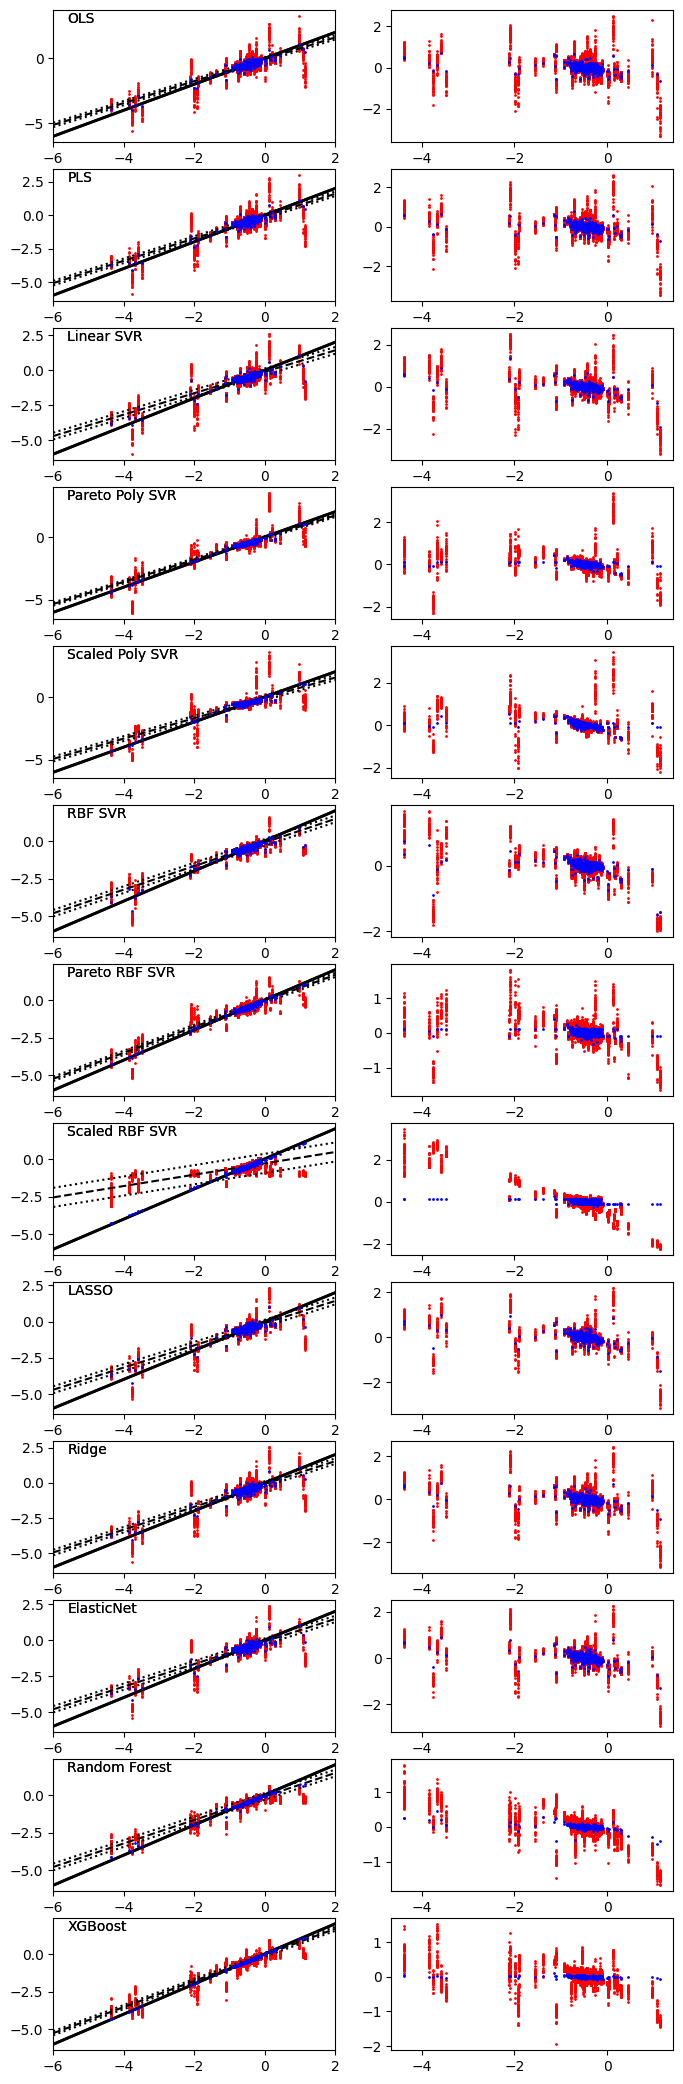

In [8]:
cvs_dict = this_study.cvs_dict
fig,axs = cvs_plots(this_study.train,cvs_dict,this_study.kfold_repeats)
calibration_plots(ytr,pred_tr,axs,color='b')

In [9]:
for name,metric in multiphase_flow_utils.score_metrics.items():
    this_study.cv_score(score_name=name,score_fun=metric)

mae
rmse
r2
mape
medae
maxe


In [10]:
paper_models = [
    'PLS',
    'LASSO',
    'Ridge',
    'OLS',
    'ElasticNet',
    'Scaled RBF SVR',
    'Random Forest',
    'XGBoost'
]

In [11]:
scores_train = {}
for name,metric in multiphase_flow_utils.score_metrics.items():
    this_score = this_study.all_score(*this_study.train,score_name=name,score_fun=metric)
    scores_train = dict(**scores_train,**this_score)
scores_train = {
    metric:{mdl:this_scores[mdl] for mdl in paper_models}
    for metric,this_scores in scores_train.items()
}
pd.DataFrame.from_dict(scores_train)

,mae,rmse,r2,mape,medae,maxe
PLS,0.126112,0.178903,0.876454,0.484192,0.088197,0.779037
LASSO,0.133496,0.203489,0.840164,0.591851,0.095240,1.503320
Ridge,0.124453,0.180365,0.874426,0.527357,0.086828,0.915935
OLS,0.124143,0.173374,0.883972,0.511440,0.089338,0.698495
ElasticNet,0.127439,0.192741,0.856602,0.587922,0.089406,1.290272
Scaled RBF SVR,0.066233,0.076630,0.977333,0.268804,0.072579,0.287870
Random Forest,0.034950,0.066570,0.982894,0.136609,0.019507,0.504412
XGBoost,0.016302,0.022254,0.998088,0.066174,0.012196,0.107462


In [12]:
scores_test = {}
for name,metric in multiphase_flow_utils.score_metrics.items():
    this_score = this_study.all_score(*this_study.test,score_name=name,score_fun=metric)
    scores_test = dict(**scores_test,**this_score)
scores_test = {
    metric:{mdl:this_scores[mdl] for mdl in paper_models}
    for metric,this_scores in scores_test.items()
}
pd.DataFrame.from_dict(scores_test)

,mae,rmse,r2,mape,medae,maxe
PLS,0.144247,0.201138,0.864191,0.399209,0.109445,0.810383
LASSO,0.135555,0.232437,0.818636,0.561615,0.086716,1.214557
Ridge,0.141783,0.199159,0.866851,0.492690,0.108631,0.829209
OLS,0.145952,0.199518,0.866370,0.421081,0.110288,0.779919
ElasticNet,0.137740,0.214448,0.845623,0.565042,0.094264,0.991755
Scaled RBF SVR,0.169920,0.385652,0.500734,0.888749,0.070802,2.796761
Random Forest,0.084811,0.167284,0.906060,0.245570,0.045440,1.347331
XGBoost,0.086765,0.148724,0.925749,0.300923,0.055080,1.130530


Text(0.5, 0, '$R^2$ score')

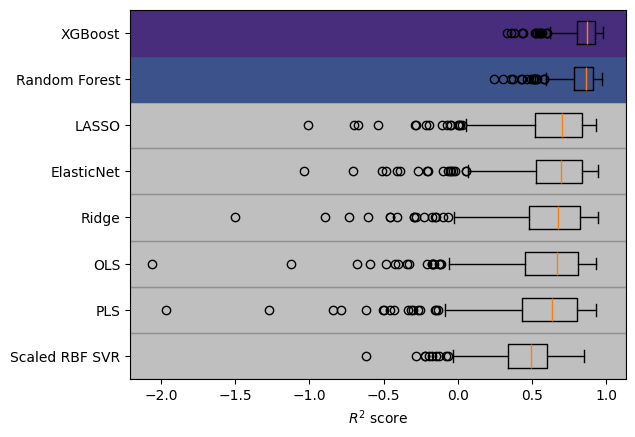

In [13]:
scores_dict = this_study.cv_scores['r2']
scores_dict = {mdl:scores_dict[mdl] for mdl in paper_models}
make_boxplot(scores_dict,this_study.kfold_repeats)
plt.gca().set_xlabel(r'$R^2$ score')

In [14]:
order = order_results(scores_dict)
order

['XGBoost',
 'Random Forest',
 'LASSO',
 'ElasticNet',
 'Ridge',
 'OLS',
 'PLS',
 'Scaled RBF SVR']

Text(0.5, 0, 'Median absolute error')

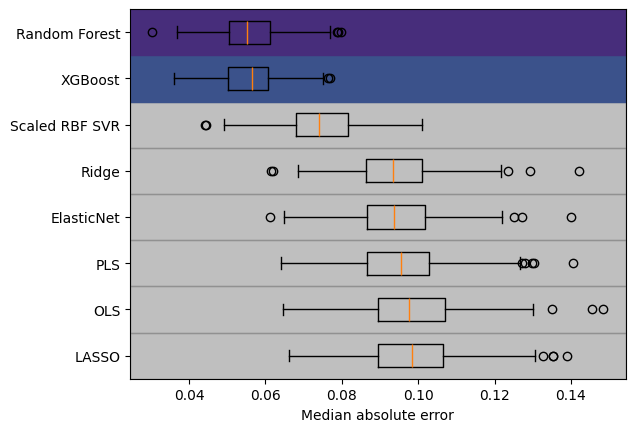

In [15]:
scores_dict = this_study.cv_scores['medae']
scores_dict = {mdl:scores_dict[mdl] for mdl in paper_models}
make_boxplot(scores_dict,this_study.kfold_repeats,reverse=False)
plt.gca().set_xlabel('Median absolute error')

Text(0.5, 0, 'Maximum absolute error')

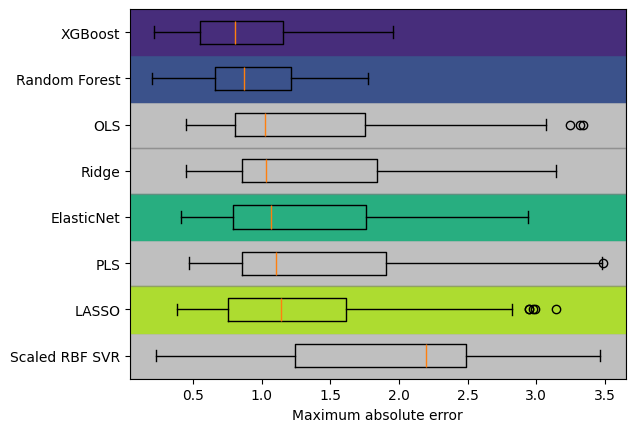

In [16]:
scores_dict = this_study.cv_scores['maxe']
scores_dict = {mdl:scores_dict[mdl] for mdl in paper_models}
make_boxplot(scores_dict,this_study.kfold_repeats,reverse=False)
plt.gca().set_xlabel('Maximum absolute error')

In [17]:
perfs = results_perform(scores_dict,this_study.kfold_repeats,alpha=0.05,reverse=False)
best_model = perfs[0][0]
good_models = []
for perf in perfs:
    if not perf[-1]: good_models += [perf[0]]

In [18]:
best_model,good_models

('XGBoost', ['XGBoost', 'Random Forest', 'ElasticNet', 'LASSO'])

In [19]:
good_models[:1]

['XGBoost']

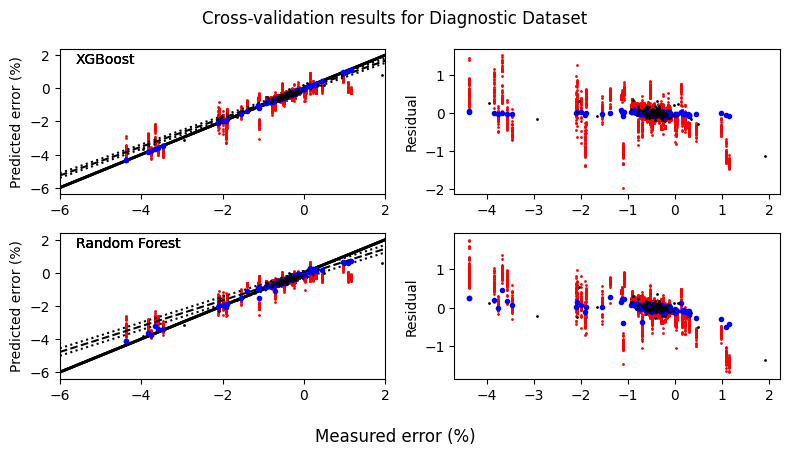

In [20]:
names_detailed = good_models[:2]
cvs_detailed = {
    key:cvs_dict[key] for key in names_detailed
}
fig,axs = cvs_plots(this_study.train,cvs_detailed,this_study.kfold_repeats)

xtr,ytr = this_study.train
xte,yte = this_study.test

pred_tr = {mdl:this_study.all_predict(xtr)[mdl] for mdl in names_detailed}
pred_te = {mdl:this_study.all_predict(xte)[mdl] for mdl in names_detailed}

nplots = len(pred_tr)
#fig,axs = plt.subplots(nplots,2,figsize=(8,2*nplots))

calibration_plots(ytr,pred_tr,axs,color='b',size=3)
calibration_plots(yte,pred_te,axs,color='k')

for ax_row in axs:
    ax_row[0].set_ylabel('Predicted error (%)')
    ax_row[1].set_ylabel('Residual')
    
fig.suptitle(
    'Cross-validation results for {} Dataset'.format(dataset_num), 
)
fig.supxlabel('Measured error (%)')
fig.tight_layout()

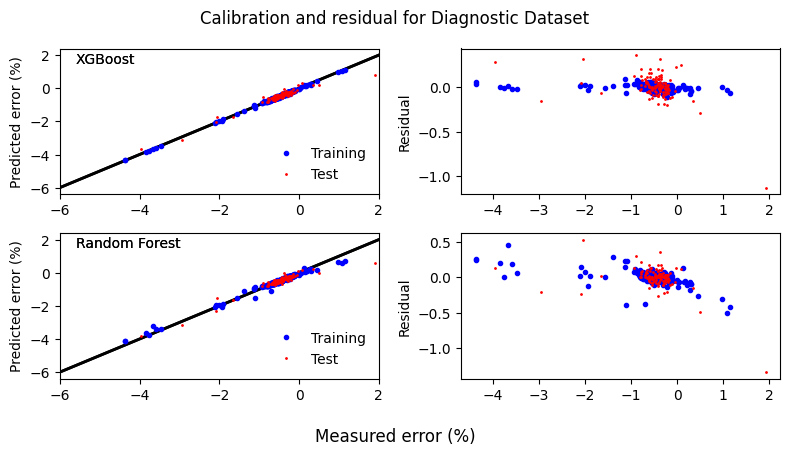

In [21]:
xtr,ytr = this_study.train
xte,yte = this_study.test

pred_tr = {mdl:this_study.all_predict(xtr)[mdl] for mdl in names_detailed}
pred_te = {mdl:this_study.all_predict(xte)[mdl] for mdl in names_detailed}

nplots = len(pred_tr)
fig,axs = plt.subplots(nplots,2,figsize=(8,2*nplots+0.5),squeeze=False)

calibration_plots(ytr,pred_tr,axs,color='b',size=3,label='Training')
calibration_plots(yte,pred_te,axs,color='r',label='Test')

fig.suptitle(
    'Calibration and residual for {} Dataset'.format(dataset_num), 
)
fig.supxlabel('Measured error (%)')
for ax_row in axs:
    ax_row[0].set_ylabel('Predicted error (%)')
    ax_row[1].set_ylabel('Residual')
    ax_row[0].legend(frameon=False)
fig.tight_layout()

In [22]:
bad_models = [mdl for mdl,score in scores_test['r2'].items() if score < 0]
if len(bad_models)>0:
    xtr,ytr = this_study.train
    xte,yte = this_study.test

    pred_tr = {mdl:this_study.all_predict(xtr)[mdl] for mdl in bad_models}
    pred_te = {mdl:this_study.all_predict(xte)[mdl] for mdl in bad_models}

    score_list = [scores_test['r2'][mdl] for mdl in bad_models]

    nplots = len(pred_tr)
    fig,axs = plt.subplots(nplots,2,figsize=(8,2*nplots+0.5),squeeze=False)

    calibration_plots(ytr,pred_tr,axs,color='b',size=3)
    calibration_plots(yte,pred_te,axs,color='r',size=3)

    fig.suptitle(
        'Calibration and residual for Dataset {}'.format(dataset_num), 
    )
    fig.supxlabel('Measured error (%)')
    for ax_row,score in zip(axs,score_list):
        ax_row[0].set_ylabel('Predicted error (%)')
        ax_row[1].set_ylabel('Residual')
        ax_row[0].text(
            0.95,0.05,'{:6.3f}'.format(score),
            ha='right',va='bottom',
            transform=ax_row[0].transAxes)
        print(score)
    fig.tight_layout()

In [23]:
import shap

In [24]:
df = this_study.train[0]
med = pd.DataFrame(
    np.median(df,axis=0)[None,:,],
    columns=df.columns
)
    
print(med.shape)
model = names_detailed[1]
print(model)

def f(x):
    #return this_study.best_models['Pareto RBF SVR'].predict(x)
    return this_study.best_models[model].predict(x)

ex1 = shap.Explainer(f,med)
shap_train = ex1(this_study.train[0],max_evals=1000)
shap_values = ex1(this_study.test[0],max_evals=1000)

shap_title_string = "SHAP values for {num} Dataset: {segm} set"

shap_plot_kw = dict(
    max_display=10,
    plot_size=(6,4),
    show=False,
)

(1, 51)
Random Forest


PermutationExplainer explainer: 488it [00:31, 12.20it/s]                         


In [25]:
df = this_study.train[0]
med = pd.DataFrame(
    np.median(df,axis=0)[None,:,],
    columns=df.columns
)
    
print(med.shape)

shap_title_string = "SHAP values for {num} Dataset: {segm} set"

shap_plot_kw = dict(
    max_display=10,
    plot_size=(6,4),
    show=False,
)

(1, 51)


In [26]:
def get_shaps(study_obj,model_name,median):
    def f(x):
        return study_obj.best_models[model_name].predict(x)
    ex1 = shap.Explainer(f,median)
    shap_train = ex1(study_obj.train[0],max_evals=1000)
    shap_values = ex1(study_obj.test[0],max_evals=1000)
    
    return ex1,shap_train,shap_values

In [27]:
def beeswarm_plot(shaps,dataset,segment,model_name):
    title = shap_title_string.format(
        num = dataset,
        segm=segment,
    )

    shap.plots.beeswarm(
        shaps,
        order=shaps.abs.max(0),
        **shap_plot_kw
    )
    fig,ax = plt.gcf(),plt.gca()
    ax.set_title(title)
    ax.text(0.1,0.1,model_name,ha='left',va='bottom',transform=ax.transAxes)
    new_labels = [
        (
            label.get_text()
            .replace('media_','mean ')
            .replace('maximo_','max ')
            .replace('desvio_padrao_','std dev ')
        )
        for label in ax.get_yticklabels()
    ]
    t = ax.set_yticklabels(new_labels)

In [29]:
model_rf = names_detailed[0]
ex_rf,shap_train_rf,shap_test_rf = get_shaps(this_study,model_rf,med)

PermutationExplainer explainer: 488it [00:20, 12.35it/s]                         


In [31]:
model_xg = names_detailed[1]
ex_xg,shap_train_xg,shap_test_xg = get_shaps(this_study,model_xg,med)

PermutationExplainer explainer: 488it [00:27, 11.37it/s]                         


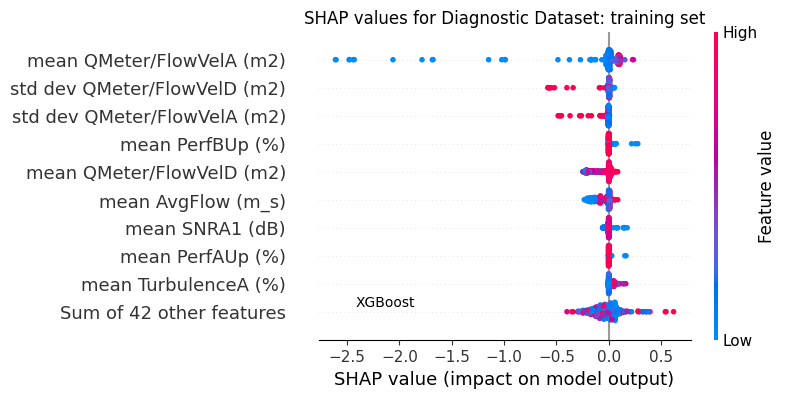

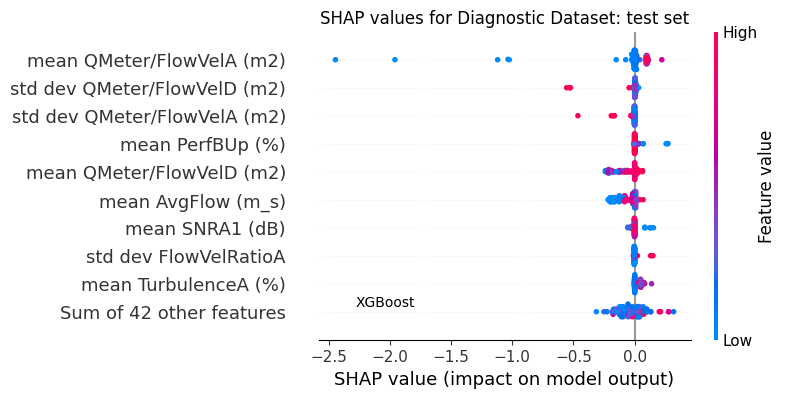

In [33]:
shaps = shap_train
segment = 'training'
beeswarm_plot(shap_train_rf,dataset_num,'training',model_rf)
plt.show()
beeswarm_plot(shap_test_rf,dataset_num,'test',model_rf)

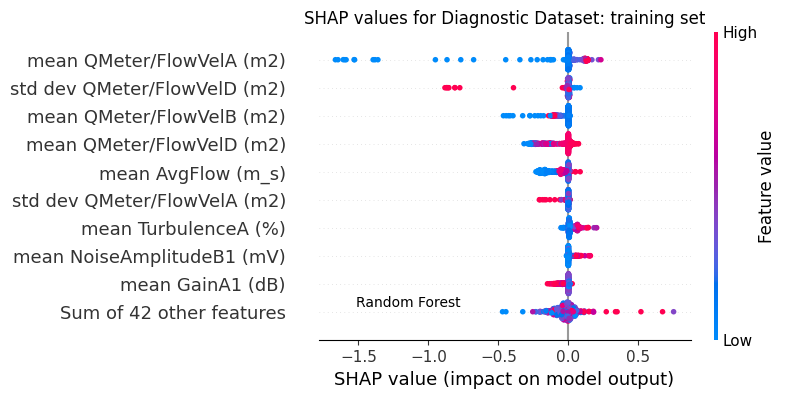

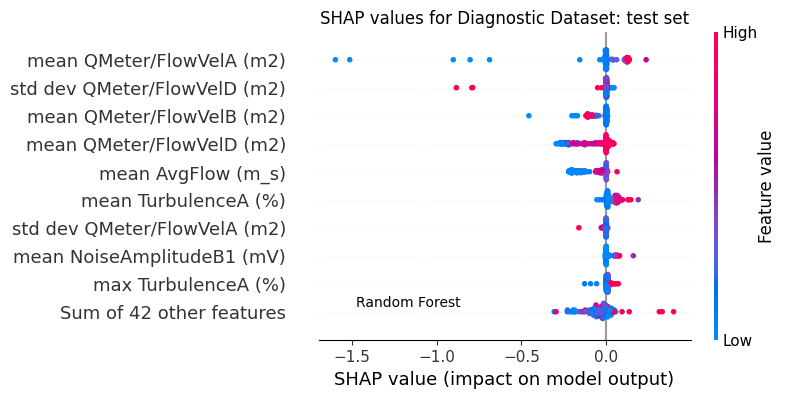

In [34]:
shaps = shap_train
segment = 'training'
beeswarm_plot(shap_train_xg,dataset_num,'training',model_xg)
plt.show()
beeswarm_plot(shap_test_xg,dataset_num,'test',model_xg)

In [35]:
for name, model in this_study.models.items():
    print(name)
    print(model.best_params_)

OLS
{'ols__fit_intercept': True, 'ols__positive': False}
PLS
{'pls__n_components': 14}
Linear SVR
{'svm__C': 0.03162277660168379}
Pareto Poly SVR
{'svm__C': 1.0, 'svm__degree': 2}
Scaled Poly SVR
{'svm__C': 0.09999999999999999, 'svm__degree': 2}
RBF SVR
{'svm__C': 100.0, 'svm__gamma': 'auto'}
Pareto RBF SVR
{'svm__C': 100.0, 'svm__gamma': 'auto'}
Scaled RBF SVR
{'svm__C': 3.162277660168379, 'svm__gamma': 'auto'}
LASSO
{'est__alpha': 0.01}
Ridge
{'est__alpha': 10.0}
ElasticNet
{'est__alpha': 0.03162277660168379, 'est__l1_ratio': 0.11920292202211755}
Random Forest
{'forest__max_depth': None, 'forest__max_features': None, 'forest__n_estimators': 100}
XGBoost
{'forest__learning_rate': 0.09999999999999999, 'forest__max_depth': 6, 'forest__num_parallel_tree': 13, 'forest__reg_alpha': 0.09999999999999999, 'forest__reg_lambda': 0.09999999999999999, 'forest__subsample': 0.6}


In [ ]:
shap_values

In [ ]:
shaps = shap_train
segment = 'training'
title = shap_title_string.format(
    num = dataset_num,
    segm=segment,
)

shap.plots.beeswarm(
    shaps,
    order=shaps.abs.max(0),
    **shap_plot_kw
)
fig,ax = plt.gcf(),plt.gca()
ax.set_title(title)
ax.text(0.1,0.1,model,ha='left',va='bottom',transform=ax.transAxes)
new_labels = [
    (
        label.get_text()
        .replace('media_','mean ')
        .replace('maximo_','max ')
        .replace('desvio_padrao_','std dev ')
    )
    for label in ax.get_yticklabels()
]
t = ax.set_yticklabels(new_labels)

In [ ]:
shaps = shap_values
segment = 'test'
title = shap_title_string.format(
    num = dataset_num,
    segm=segment,
)

shap.plots.beeswarm(
    shaps,
    order=shaps.abs.max(0),
    **shap_plot_kw
)
fig,ax = plt.gcf(),plt.gca()
ax.set_title(title)
new_labels = [
    (
        label.get_text()
        .replace('media_','mean ')
        .replace('maximo_','max ')
        .replace('desvio_padrao_','std dev ')
    )
    for label in ax.get_yticklabels()
]
t = ax.set_yticklabels(new_labels)

In [ ]:
[
    (
        label.get_text()
        .replace('media_','mean ')
        .replace('maximo_','max ')
        .replace('desvio_padrao_','std dev ')
    )
    for label in ax.get_yticklabels()
]

In [ ]:
this_study.cvs_dict

In [ ]:
import matplotlib

In [ ]:
scores = {}
for name,metric in multiphase_flow_utils.score_metrics.items():
    this_score = this_study.all_score(*this_study.train,score_name=name,score_fun=metric)
    #print(this_score)
    scores = dict(**scores,**this_score)

pd.DataFrame.from_dict(scores)

In [ ]:
scores_dict = this_study.cv_scores['r2']
make_boxplot(scores_dict,this_study.kfold_repeats)

In [ ]:
scores_dict = this_study.cv_scores['medae']
make_boxplot(scores_dict,this_study.kfold_repeats,reverse=False)

In [ ]:
scores_dict = this_study.cv_scores['medae']

# ignore = np.nan
# if np.isnan(ignore):
#     key = lambda k: np.median(
#         np.asarray(scores_dict[k])[~np.isnan(scores_dict[k])]
#     )
# else:
#     key = lambda k: np.median(
#         np.asarray(scores_dict[k])[np.asarray(scores_dict[k]) != ignore]
#     )

# order = sorted(scores_dict, key=key, reverse=False)

order = order_results(scores_dict,reverse=False)

fig,ax = plt.subplots()

h = ax.boxplot(
    [scores_dict[name] for name in order][::-1],
    #[scr for name,scr in scores_dict.items()],
    tick_labels=order[::-1],
    vert=False
)
#ax.invert_xaxis()
#ax.set_ylim(-1,1)

#for name,scr in scores_dict.items():
#    ax.boxplot(scr)